# Viability

> Can selling part of the readjusted land pay for the tunnel?

1. **Cost.** What the tunnel would cost, from three angles.
2. **Uplift on existing homes.** Notebook 04's estimate, for comparison.
3. **Development value.** The land value of the new homes a readjustment around the Rotherhithe
   portal could deliver, net of rebuilding the homes it replaces.
4. **The split.** How that value divides between the tunnel (reserve land sold to fund it) and
   the existing owners, in present values.

All money is in 2025 prices.

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tunnel.config import (
    BNG,
    CATCHMENT_M,
    COLOURS,
    DERIVED,
    FIGURES,
    PRICE_YEAR,
    catchment,
    tunnel_length_m,
    use_style,
)
from tunnel.data import OA_BOUNDARIES, households, land_values, ons_layer, real
from tunnel.ownership import constraints, rotherhithe_side

use_style()

## Assumptions

In [ ]:
# Development
REDEVELOP_SHARES = [0.20, 0.35, 0.50]  # share of developable land actually rebuilt
TARGET_DENSITIES = [260, 400]  # homes/ha: Southwark "high" in MHCLG; Tower Hamlets "high"
RESERVE_SHARES = [0.30, 0.40]  # land kept back and sold to fund infrastructure (Japanese schemes ~35-40%)
BUILD_COST_PER_HOME = 340_000  # replacement home: ~85 m² GIA × £4,000/m², all-in (assumption, not BCIS)

# Phasing (years counted from the decision to proceed; year 0 = today)
DELIVERY_PER_YEAR = 500  # net new homes completed per year
FIRST_COMPLETIONS_YEAR = 6  # masterplan, readjustment vote and planning, then build, alongside the tunnel
LAND_SALE_LEAD_YEARS = 2  # each tranche of reserve land sells ~2 years before its homes complete
CONSTRUCTION_YEARS = [2, 3, 4, 5]  # tunnel spend, after ~2 years of design and consents
DISCOUNT_RATES = {"3.5% (Green Book)": 0.035, "7% (commercial)": 0.07}

# The scenario quoted in the blog
HEADLINE = {"redeveloped share": "35%", "target homes/ha": 400, "reserve share": "40%"}
HEADLINE_RATE = "3.5% (Green Book)"

## 1 · Tunnel cost

- **A. Top-down.** TfL's November 2017 options report costed an immersed tunnel on this crossing
  at £325m to £335m. We inflate that with the GDP deflator.
- **B. Bottom-up.** HS2's *Guide to Tunnelling Costs* (2011 unit rates) for a TBM, site set-up,
  bored metres, time on site, shafts and fit-out, plus optimism bias.
- **C. Benchmark.** The IPA/BTS short-tunnel benchmark of £5.63m per km per m² of face area
  (2016/17), plus B's shafts, plus optimism bias.

In [ ]:
TUNNEL_M = tunnel_length_m()
A = {"low": real(325, 2017), "central": real(330, 2017), "high": real(335, 2017)}

# B: HS2's twin-bore rate is £22-25k per route metre, so halve it for one bore and scale by face
# area from HS2's ~8.8 m outside diameter to our ~7 m (a ~6 m internal diameter with a cycle
# track and footway). Shafts: HS2 puts a ventilation shaft with lift and head house at £10-30m.
OD_M, HS2_OD_M = 7.0, 8.8
face = (OD_M / HS2_OD_M) ** 2
hs2 = pd.DataFrame(
    {
        "low": [16, 35, 22e3 / 2 * face * TUNNEL_M / 1e6, 1.1 * 52, 2 * 15, 4e3 * TUNNEL_M / 1e6],
        "central": [17, 40, 23.5e3 / 2 * face * TUNNEL_M / 1e6, 1.1 * 78, 2 * 25, 4e3 * TUNNEL_M / 1e6],
        "high": [18, 45, 25e3 / 2 * face * TUNNEL_M / 1e6, 1.1 * 104, 2 * 30, 6e3 * TUNNEL_M / 1e6],
    },
    index=[
        "TBM (purchase/refurb)",
        "fixed site set-up (both portals)",
        "bored tunnel",
        "time-related (weeks on site)",
        "shafts + lifts + entrance buildings (×2)",
        "M&E fit-out",
    ],
).map(lambda v: real(v, 2011))
shafts = hs2.loc["shafts + lifts + entrance buildings (×2)"]

# C: tunnel only from the benchmark, then B's shafts
ipa_tunnel = real(5.63 * np.pi * (OD_M / 2) ** 2 * TUNNEL_M / 1000, 2016)

# Green Book optimism bias at outline business case: 44% standard, 66% non-standard civil engineering
OB = {"low": 0.44, "central": 0.55, "high": 0.66}
cost = pd.DataFrame(
    {
        "A: TfL 2017 immersed tunnel, inflated": A,
        "B: HS2 unit rates + optimism bias": {k: hs2[k].sum() * (1 + OB[k]) for k in OB},
        "C: IPA benchmark + shafts + optimism bias": {k: (ipa_tunnel + shafts[k]) * (1 + OB[k]) for k in OB},
    }
).T
COST = {"low": cost["low"].min(), "central": cost.loc[cost.index[0], "central"], "high": cost["high"].max()}
print(f"Tunnel length {TUNNEL_M:.0f} m. Working cost (£m): " + ", ".join(f"{k} {v:.0f}" for k, v in COST.items()))
cost.round(0)

Tunnel length 506 m. Working cost (£m): low 277, central 440, high 594


,low,central,high
"A: TfL 2017 immersed tunnel, inflated",434.0,440.0,447.0
B: HS2 unit rates + optimism bias,303.0,450.0,594.0
C: IPA benchmark + shafts + optimism bias,277.0,344.0,393.0


The central cost is TfL's own estimate for this crossing, inflated. B and C, built up from other
tunnels, bracket it. Spread evenly over the construction years and discounted:

In [ ]:
def pv_spread(amount: float, years: list[int], rate: float) -> float:
    return amount * np.mean([(1 + rate) ** -t for t in years])


pv_cost = {
    label: {k: pv_spread(v, CONSTRUCTION_YEARS, r) for k, v in COST.items()} for label, r in DISCOUNT_RATES.items()
}
pd.DataFrame(pv_cost).T.round(0).rename(columns=lambda c: f"PV cost {c} (£m)")

,PV cost low (£m),PV cost central (£m),PV cost high (£m)
3.5% (Green Book),246.0,391.0,527.0
7% (commercial),220.0,349.0,470.0


## 2 · Uplift on existing homes

In [ ]:
oa_uplift = pd.read_csv(DERIVED / "oa_uplift.csv")
uplift = {s: oa_uplift[f"uplift_gbp_{s}"].sum() / 1e6 for s in ("Low", "Central", "High")}
print(
    f"Central uplift on existing homes: £{uplift['Central']:.0f}m, "
    f"{uplift['Central'] / COST['central']:.0%} of the £{COST['central']:.0f}m central cost"
)

Central uplift on existing homes: £76m, 17% of the £440m central cost


## 3 · Development value

### The readjustment area

Output areas clipped to the Rotherhithe side of the `CATCHMENT_M` circle (the same area as the
ownership notebook), with Census households prorated by area. Parks, water, schools and places
of worship are not developable.

In [ ]:
side = rotherhithe_side(catchment())
oa = ons_layer(OA_BOUNDARIES).to_crs(BNG)[["OA21CD", "geometry"]].merge(households(), on="OA21CD")
oa["oa_area"] = oa.area
area = gpd.clip(oa, side)
area["households"] = area.households * area.area / area.oa_area
area["geometry"] = area.geometry.difference(constraints(side).union_all())
dev_ha = area.area.sum() / 1e4
existing_dph = area.households.sum() / dev_ha
print(
    f"{side.area / 1e4:.0f} ha in the area, {dev_ha:.1f} ha developable, {area.households.sum():,.0f} households ({existing_dph:.0f} per developable ha)"
)

111 ha in the area, 59.0 ha developable, 3,675 households (62 per developable ha)


### Land value per new home

MHCLG's 2023 residential land values for Southwark at its "high density" assumption, at the median
house price, per home. At 400 homes/ha we keep that per-home value: taller buildings cost more per
home to build, which roughly offsets the extra homes.

In [ ]:
southwark = land_values().loc["Southwark"]
lv_per_home = real(southwark["high_50"] / southwark["dph_high"], 2023)
print(
    f"Southwark: £{southwark['high_50'] / 1e6:.1f}m/ha at {southwark['dph_high']:.0f} homes/ha (2023) → £{lv_per_home:,.0f} per home"
)

Southwark: £63.6m/ha at 260 homes/ha (2023) → £263,616 per home


### Tunnel premium on new homes

New homes near the portal also gain the tunnel's uplift. We take notebook 04's central uplift,
weighted by developable area, applied to the median SE16 new-build flat price.

In [ ]:
sales = pd.read_csv(DERIVED / "sales.csv")
new_flats = sales[
    (sales.district == "SE16") & (sales.new_build == "Y") & (sales.property_type == "F") & (sales.year >= 2021)
]
new_home_price = new_flats.price.median()
w = area.assign(ha=area.area / 1e4).set_index("OA21CD").ha
pct = oa_uplift.set_index("OA21CD").reindex(w.index)
premium = {
    s: float((pct[f"uplift_pct_{s}"] * w).sum() / w[pct[f"uplift_pct_{s}"].notna()].sum()) for s in ("Central", "High")
}
print(f"Median SE16 new-build flat 2021+: £{new_home_price:,.0f} (n={len(new_flats)})")
print("Tunnel premium:", {k: f"{v:.1%}" for k, v in premium.items()})

Median SE16 new-build flat 2021+: £610,000 (n=115)
Tunnel premium: {'Central': '3.5%', 'High': '25.8%'}


### Scenarios

Redevelopment replaces the homes on the rebuilt land (`homes demolished & replaced`) and adds the
rest as `net new homes`. The land value of the net new homes is the prize. A reserve share of it
is sold to fund the tunnel; existing owners keep the rest after paying to rebuild their homes.
Receipts and replacement costs follow a build-out of `DELIVERY_PER_YEAR` homes a year, with land
sold `LAND_SALE_LEAD_YEARS` ahead of completions.

In [ ]:
def pv_factor(net_new: float, rate: float, per_year: float = DELIVERY_PER_YEAR) -> float:
    "Average discount factor over the build-out of `net_new` homes."
    if net_new <= 0:
        return 1.0
    full, part = divmod(net_new, per_year)
    tranches = [per_year] * int(full) + ([part] if part else [])
    first = FIRST_COMPLETIONS_YEAR - LAND_SALE_LEAD_YEARS
    return sum(n / (1 + rate) ** (first + i) for i, n in enumerate(tranches)) / net_new


rows = []
for share in REDEVELOP_SHARES:
    for target in TARGET_DENSITIES:
        redeveloped_ha = dev_ha * share
        demolished = redeveloped_ha * existing_dph
        net_new = redeveloped_ha * max(target - existing_dph, 0)
        for case, prem in premium.items():
            land_value = net_new * (lv_per_home + prem * new_home_price)
            replacement = demolished * BUILD_COST_PER_HOME
            for reserve in RESERVE_SHARES:
                row = {
                    "redeveloped share": f"{share:.0%}",
                    "target homes/ha": target,
                    "tunnel premium case": case,
                    "reserve share": f"{reserve:.0%}",
                    "redeveloped ha": redeveloped_ha,
                    "homes demolished & replaced": demolished,
                    "net new homes": net_new,
                    "build-out years": np.ceil(net_new / DELIVERY_PER_YEAR),
                    "land value (£m)": land_value / 1e6,
                    "  of which due to tunnel (£m)": net_new * prem * new_home_price / 1e6,
                    "reserve land funding (£m)": reserve * land_value / 1e6,
                    "replacement build cost (£m)": replacement / 1e6,
                    "left for owners (£m)": ((1 - reserve) * land_value - replacement) / 1e6,
                }
                for label, rate in DISCOUNT_RATES.items():
                    f = pv_factor(net_new, rate)
                    for k in ("land value", "reserve land funding", "replacement build cost", "left for owners"):
                        row[f"PV {k} @ {label} (£m)"] = row[f"{k} (£m)"] * f
                rows.append(row)
scen = pd.DataFrame(rows)
scen.to_csv(DERIVED / "development_scenarios.csv", index=False)

central = scen[scen["tunnel premium case"] == "Central"]
central.pivot_table(
    index=["redeveloped share", "target homes/ha", "build-out years"],
    columns="reserve share",
    values=[f"PV reserve land funding @ {l} (£m)" for l in DISCOUNT_RATES],
).round(0)

PV reserve land funding @ 3.5% (Green Book) (£m)  \
reserve share                                                                                  30%   
redeveloped share target homes/ha build-out years                                                    
20%               260             5.0                                                        163.0   
                  400             8.0                                                        264.0   
35%               260             9.0                                                        270.0   
                  400             14.0                                                       420.0   
50%               260             12.0                                                       364.0   
                  400             20.0                                                       547.0   

                                                          \
reserve share                                        40%   
redeveloped share target homes/ha build-out years          
20%               260             5.0              218.0   
                  400             8.0              353.0   
35%               260             9.0              360.0   
                  400             14.0             560.0   
50%               260             12.0             486.0   
                  400             20.0             729.0   

                                                  PV reserve land funding @ 7% (commercial) (£m)  \
reserve share                                                                                30%   
redeveloped share target homes/ha build-out years                                                  
20%               260             5.0                                                      135.0   
                  400             8.0                                                      208.0   
35%               260             9.0                                                      212.0   
                  400             14.0                                                     305.0   
50%               260             12.0                                                     272.0   
                  400             20.0                                                     369.0   

                                                          
reserve share                                        40%  
redeveloped share target homes/ha build-out years         
20%               260             5.0              180.0  
                  400             8.0              277.0  
35%               260             9.0              282.0  
                  400             14.0             406.0  
50%               260             12.0             363.0  
                  400             20.0             492.0

### Reserve funding as a share of the tunnel's cost

Both in present values, central cost, central premium.

In [ ]:
out = {}
for label in DISCOUNT_RATES:
    wide = central.assign(
        label=central["redeveloped share"] + " rebuilt @ " + central["target homes/ha"].astype(str) + "/ha"
    ).pivot_table(index="label", columns="reserve share", values=f"PV reserve land funding @ {label} (£m)", sort=False)
    for rs in wide.columns:
        out[(label, f"{rs} reserve")] = (wide[rs] / pv_cost[label]["central"]).map("{:.0%}".format)
pd.DataFrame(out)

3.5% (Green Book)             7% (commercial)            
                           30% reserve 40% reserve     30% reserve 40% reserve
label                                                                         
20% rebuilt @ 260/ha               42%         56%             39%         52%
20% rebuilt @ 400/ha               68%         90%             60%         80%
35% rebuilt @ 260/ha               69%         92%             61%         81%
35% rebuilt @ 400/ha              108%        143%             87%        117%
50% rebuilt @ 260/ha               93%        124%             78%        104%
50% rebuilt @ 400/ha              140%        187%            106%        141%

### Sensitivity: delivery rate

The headline scenario at different build-out speeds.

In [ ]:
h = central[(central[list(HEADLINE)] == pd.Series(HEADLINE)).all(axis=1)].iloc[0]
pd.DataFrame(
    {
        f"{n} homes/yr": {
            "build-out years": np.ceil(h["net new homes"] / n),
            **{
                f"PV reserve funding @ {l} (£m)": h["reserve land funding (£m)"] * pv_factor(h["net new homes"], r, n)
                for l, r in DISCOUNT_RATES.items()
            },
        }
        for n in (300, 500, 800, 1200)
    }
).round(0)

,300 homes/yr,500 homes/yr,800 homes/yr,1200 homes/yr
build-out years,24.0,14.0,9.0,6.0
PV reserve funding @ 3.5% (Green Book) (£m),486.0,560.0,609.0,639.0
PV reserve funding @ 7% (commercial) (£m),316.0,406.0,474.0,519.0


## 4 · The split

The headline scenario, in present values at the Green Book rate.

In [ ]:
label = HEADLINE_RATE
pv = {
    k: h[f"PV {k} @ {label} (£m)"]
    for k in ("land value", "reserve land funding", "replacement build cost", "left for owners")
}
tunnel_pv = pv_cost[label]["central"]
split = pd.Series(
    {
        "Land value of net new homes": pv["land value"],
        "Reserve land sold: funds the tunnel": pv["reserve land funding"],
        "  tunnel cost": tunnel_pv,
        "  surplus for public space and contingency": pv["reserve land funding"] - tunnel_pv,
        "Kept by existing owners": pv["land value"] - pv["reserve land funding"],
        "  rebuilding the homes replaced": pv["replacement build cost"],
        "  owners' net gain": pv["left for owners"],
    }
)
print(
    f"Headline: {HEADLINE['redeveloped share']} of {dev_ha:.0f} developable ha rebuilt at {HEADLINE['target homes/ha']} homes/ha, "
    f"{HEADLINE['reserve share']} reserve: {h['net new homes']:,.0f} net new homes, "
    f"{h['homes demolished & replaced']:,.0f} replaced, {h['build-out years']:.0f}-year build-out"
)
split.round(0).to_frame(f"£m PV @ {label}")

Headline: 35% of 59 developable ha rebuilt at 400 homes/ha, 40% reserve: 6,978 net new homes, 1,286 replaced, 14-year build-out


,£m PV @ 3.5% (Green Book)
Land value of net new homes,1401.0
Reserve land sold: funds the tunnel,560.0
tunnel cost,391.0
surplus for public space and contingency,170.0
Kept by existing owners,840.0
rebuilding the homes replaced,308.0
owners' net gain,533.0


## Figures

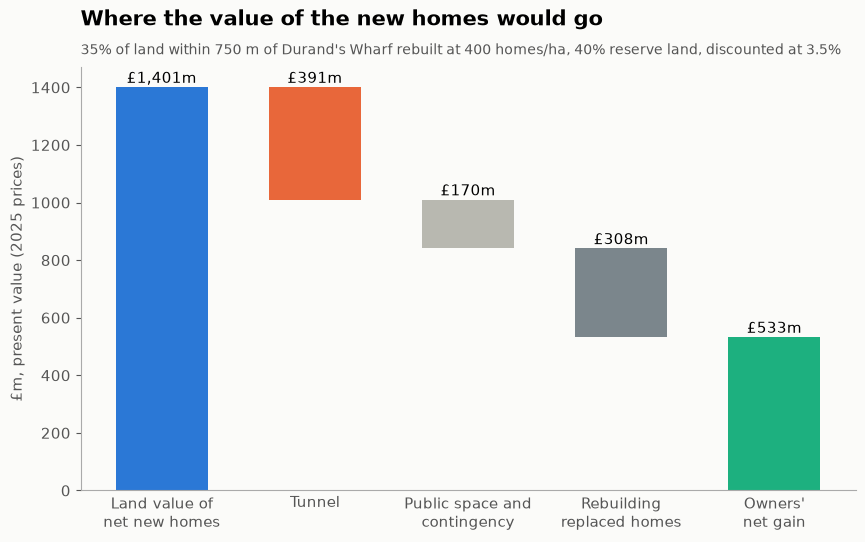

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.5))
steps = [
    ("Land value of\nnet new homes", 0, pv["land value"], COLOURS["southwark"]),
    ("Tunnel", pv["land value"] - tunnel_pv, tunnel_pv, COLOURS["tunnel"]),
    (
        "Public space and\ncontingency",
        pv["land value"] - pv["reserve land funding"],
        pv["reserve land funding"] - tunnel_pv,
        COLOURS["rest"],
    ),
    ("Rebuilding\nreplaced homes", pv["left for owners"], pv["replacement build cost"], COLOURS["jubilee"]),
    ("Owners'\nnet gain", 0, pv["left for owners"], COLOURS["other"]),
]
for i, (name, bottom, height, colour) in enumerate(steps):
    ax.bar(i, height, bottom=bottom, color=colour, width=0.6)
    ax.text(i, bottom + height + 15, f"£{height:,.0f}m", ha="center", fontsize=11)
ax.set_xticks(range(len(steps)), [s[0] for s in steps])
ax.set_ylabel(f"£m, present value ({PRICE_YEAR} prices)")
ax.tick_params(axis="x", length=0)
ax.set_title("Where the value of the new homes would go", pad=30)
ax.text(
    0,
    1.03,
    f"{HEADLINE['redeveloped share']} of land within {CATCHMENT_M} m of Durand's Wharf rebuilt at {HEADLINE['target homes/ha']} homes/ha, "
    f"{HEADLINE['reserve share']} reserve land, discounted at {label.split()[0]}",
    transform=ax.transAxes,
    color=COLOURS["text"],
    fontsize=10,
)
fig.savefig(FIGURES / "value_split.png")

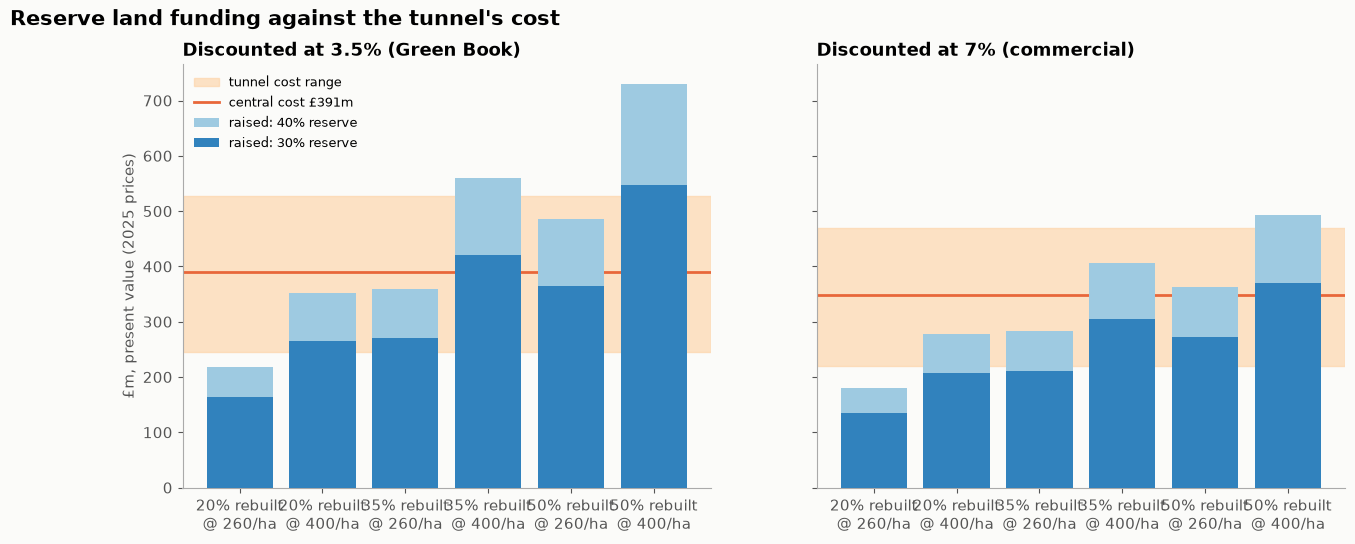

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
labelled = central.assign(
    label=central["redeveloped share"] + " rebuilt\n@ " + central["target homes/ha"].astype(str) + "/ha"
)
for ax, label in zip(axes, DISCOUNT_RATES):
    wide = labelled.pivot_table(
        index="label", columns="reserve share", values=f"PV reserve land funding @ {label} (£m)", sort=False
    )
    c = pv_cost[label]
    ax.axhspan(c["low"], c["high"], color="#fdd0a2", alpha=0.6, label="tunnel cost range")
    ax.axhline(c["central"], color=COLOURS["tunnel"], lw=2, label=f"central cost £{c['central']:.0f}m")
    x = np.arange(len(wide))
    ax.bar(x, wide["40%"], color="#9ecae1", label="raised: 40% reserve", zorder=3)
    ax.bar(x, wide["30%"], color="#3182bd", label="raised: 30% reserve", zorder=3)
    ax.set_xticks(x, wide.index)
    ax.set_title(f"Discounted at {label}", fontsize=13)
axes[0].set_ylabel(f"£m, present value ({PRICE_YEAR} prices)")
axes[0].legend(loc="upper left", fontsize=9)
fig.suptitle("Reserve land funding against the tunnel's cost", x=0.01, ha="left", fontsize=15, fontweight="bold")
fig.savefig(FIGURES / "funding_vs_cost.png")